# From question to answer: assistant walkthrough (detailed)

*Narrated version with more examples. The short version is
[02_question_to_answer_concise.ipynb](02_question_to_answer_concise.ipynb); the graph itself is
built in [01_kg_construction_detailed.ipynb](01_kg_construction_detailed.ipynb).*

This notebook follows one technician question from their words to the released answer.

> **08:20, 14 Oct.** *"The outfeed belt stopped twice after the carton changeover. The drive says
> motor overload. What should I check next?"*

| # | Step | Done by | Output |
|---|---|---|---|
| 1 | Records time | code | the part of the graph the technician could know about at 08:20 |
| 2–3 | Investigate | agent, using read-only graph tools | evidence cards with exact source lines |
| 4 | Draft | agent | findings, possible causes, next steps, one question, each claim cited |
| 5 | Check | code | citation and section rules |
| 6 | Verify | agent, one call per claim | supported or rejected, with a reason |
| 7 | Release | code | verified claims, records rendered by code, safety boundary |

Then: a follow-up, an unclear machine, a forbidden request and the source-text fallback.

**Design principle (same as construction):** agents read and write; code decides what is
allowed to reach the technician.

Runs in **replay mode**: model outputs recorded in `notebooks/recorded/answers.json` during a
live `gpt-4.1-mini` run are reused, so no API key is needed. Graph tools, checks and release run
live. Passage search uses word matching here; the app adds embedding similarity.

In [1]:
import sys, tempfile
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path[:0] = [str(ROOT / "src"), str(ROOT / "notebooks")]

import pandas as pd
from dotenv import load_dotenv
from factory_assistant.answer_models import ClaimReview
from factory_assistant.answer_ui import conversation_context
from factory_assistant.assistant import (CLAIM_INSTRUCTIONS, answer_contract, answer_question,
                                         response_issues, stock_numbers)
from factory_assistant.assistant_contracts import ResponseDraft, SupportedClaim
from factory_assistant.pipeline import build_knowledge
from factory_assistant.query_tools import GraphTools
from answer_walkthrough import (RecordedAssistant, card_sources, checks_table, context_table,
                                draft_table, draw_answer_flow, investigation_table, show_answer,
                                sources_table, claim_lines, tool_table, touched_nodes)
from kg_walkthrough import draw_graph, evidence_frame, short, to_networkx
%matplotlib inline

MODE = "replay"  # "live" calls the model for questions not recorded yet (needs OPENAI_API_KEY in .env)
load_dotenv(ROOT / ".env")
RUNTIME = Path(tempfile.mkdtemp(prefix="answer-walkthrough-"))
bundle = build_knowledge(ROOT, RUNTIME)  # notebook 01's graph, replayed from agent_cache/
agent = RecordedAssistant(ROOT / "notebooks" / "recorded" / "answers.json", mode=MODE)

DATASET, AS_OF = "initial-incident", "2026-10-14T08:20:00+08:00"
QUESTION = ("The outfeed belt stopped twice after the carton changeover. "
            "The drive says motor overload. What should I check next?")
print(f"Graph: {len(bundle.nodes)} nodes, {len(bundle.edges)} links · answers: {MODE} · records as of {AS_OF}")

Graph: 66 nodes, 53 links · answers: replay · records as of 2026-10-14T08:20:00+08:00


In [2]:
def ask(question, as_of=AS_OF):
    """Run the assistant exactly as the app does; keep the request's tools for inspection."""
    tools = GraphTools(bundle, DATASET, as_of, question)
    agent.calls.clear()
    result = answer_question(bundle, question, as_of, DATASET, RUNTIME, mode="live",
                             search_mode="keyword", agent=agent, retrieval_tools=tools)
    return result, tools

## 0. The answering path

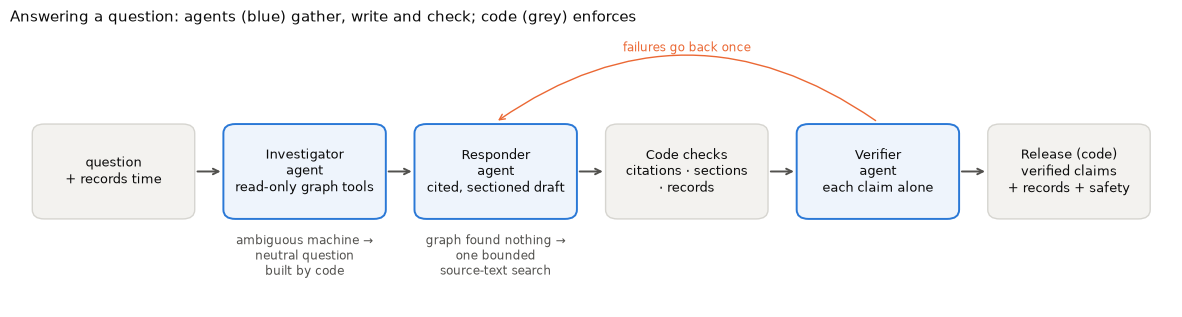

In [3]:
draw_answer_flow()

## 1. Records time: what the assistant may see

Every question has a time. The request's view keeps only files registered by then, and only
events, stock counts and cases dated by then. A citation whose text no longer matches its file is
dropped. The technician at 08:20 cannot be answered with Friday's closeout.

In [4]:
tools = GraphTools(bundle, DATASET, AS_OF, QUESTION)
documents = [n.properties for n in bundle.nodes if n.kind == "Document"]
display(pd.DataFrame([
    {"id": p["source_id"], "file": p["path"].rsplit("/", 1)[-1],
     "registered": p["recorded_at"][:16].replace("T", " "),
     "visible at 08:20": "yes" if p["source_id"] in tools.documents else "no (added later)"}
    for p in sorted(documents, key=lambda p: p["recorded_at"])
]))
print(f"Visible: {len(tools.nodes)} of {len(bundle.nodes)} nodes, {len(tools.edges)} of {len(bundle.edges)} links")

,id,file,registered,visible at 08:20
0,E6,CT-200_configuration_A_rev1.pdf,2025-11-01 09:00,yes
1,E5,CT-200_configuration_B_rev3.pdf,2026-09-01 09:00,yes
2,E8,site_maintenance_boundaries.txt,2026-10-01 09:00,yes
3,E1,equipment_notes.txt,2026-10-12 15:00,yes
4,E7a,approved_parts.txt,2026-10-12 15:30,yes
5,E7b,stores_snapshot.txt,2026-10-13 16:00,yes
6,E4,maintenance_history.txt,2026-10-13 17:00,yes
7,E3,shift_handover.txt,2026-10-14 08:15,yes
8,E2,morning_export.log,2026-10-14 08:16,yes
9,N1,friday_closeout.txt,2026-10-16 09:10,no (added later)


Visible: 47 of 66 nodes, 40 of 53 links


## 2. The investigator's toolbox

The investigator never writes a query. Each turn it picks **one** of these typed, read-only
functions (at most ten turns). Arguments are validated, and IDs must come from earlier results.

In [5]:
tool_table(tools.definitions())

,tool,arguments,what it does
0,find_equipment,query,Find equipment by ID/name/alias
1,walk_graph,"start_id, relations, direction, hops",Follow selected graph links up to three hops from a previously returned node
2,query_events,"equipment_id, event_code, since",Retrieve dated events on a resolved machine and its components
3,search_passages,"query, equipment_id, limit",Search eligible passages using words plus optional embedding similarity
4,search_documents,"query, limit","Fallback: search the source text of every file available at the question time, for what the other tools …"
5,query_history,equipment_id,Read up to ten dated maintenance cases for resolved equipment and its components
6,approved_parts,equipment_id,Find explicitly approved parts through equipment -> configuration <- part links
7,query_stock,equipment_id,Get reviewed stock counts for this machine's explicitly approved parts
8,troubleshooting_context,equipment_id,"For a stoppage or alarm on one resolved machine, gather its context in one graph traversal: installed …"
9,finish_retrieval,"outcome, question","Finish when the evidence covers the question, when the technician must clarify (ask one neutral …"


## 3. The tools by hand (no model)

The same calls the agent will make, run directly to show what they return.

### 3a. Which machine?

In [6]:
found = tools.execute("find_equipment", {"query": "outfeed belt"})
print("find_equipment('outfeed belt') →", "resolved" if found["resolved"] else "not resolved",
      [m["node_id"] for m in found["matches"]])
evidence_frame(tools.cards["node:CV-01"].evidence)

find_equipment('outfeed belt') → resolved ['CV-01']


,source,file,line,page,exact text in the file
0,E1,equipment_notes.txt,4,,Line 1: carton packer -> CV-01 -> LB-01 labeller
1,E1,equipment_notes.txt,5,,"CV-01 = ""outfeed belt"" / ""packing outfeed"". Model CT-200, configuration B."


"outfeed belt" is a recorded alias of CV-01 (walkdown notes, line 5). A machine resolves only
when the technician's own words name it, so the model cannot invent an identity.

In [7]:
vague = GraphTools(bundle, DATASET, AS_OF, "The outfeed stopped.")
found = vague.execute("find_equipment", {"query": "outfeed"})
print("find_equipment('outfeed') →", "resolved" if found["resolved"] else "not resolved; candidates",
      [m["node_id"] for m in found["matches"]])
try:
    vague.execute("troubleshooting_context", {"equipment_id": "CV-01"})
except ValueError as exc:
    print("troubleshooting_context('CV-01') → refused:", exc)

find_equipment('outfeed') → not resolved; candidates ['CV-01', 'CV-02']
troubleshooting_context('CV-01') → refused: Resolve the equipment before gathering its context.


"outfeed" alone could be CV-01 or CV-02. The tools refuse to work on a machine that is not
resolved, so nothing downstream can run on a guess.

### 3b. One call gathers the incident: `troubleshooting_context`

In [8]:
ctx = tools.execute("troubleshooting_context", {"equipment_id": "CV-01"})
context_table(ctx, tools.cards)

,context,found,from files
0,machine,"CV-01, aliases ['outfeed belt', 'packing outfeed']",equipment_notes.txt
1,applicable manual,CT200-B rev 3 (via configuration B),"CT-200_configuration_B_rev3.pdf, equipment_notes.txt"
2,manual sections,"1. Applicability, 2. Motor overload, 3. Inspection boundary, 4. Replacement reference, 5. Other stops",CT-200_configuration_B_rev3.pdf
3,recorded events,"MOTOR_OVERLOAD × 2, RUNNING × 1",morning_export.log
4,alarm definitions,MOTOR_OVERLOAD: The simulated drive label MOTOR_OVERLOAD means motor …,CT-200_configuration_B_rev3.pdf
5,shift observations,"5 notes, of which 1 unverified suspicion",shift_handover.txt
6,past cases,"J-108 (setup then: unknown), J-071 (setup then: different recorded configuration)",maintenance_history.txt
7,procedures,SITE-M01 (full text in folder: False),"CT-200_configuration_B_rev3.pdf, site_maintenance_boundaries.txt"


In [9]:
path = ctx["applicable_manuals"][0]["applicability_path"]
print("Why manual E5 applies (a path card the responder can cite):\n ", tools.cards[path].text)
files = sorted({r.path.rsplit("/", 1)[-1] for c in tools.cards.values() for r in c.evidence})
print(f"\nOne call, {len(files)} files:", ", ".join(files))

Why manual E5 applies (a path card the responder can cite):
  [{"source": "CV-01", "relation": "HAS_CONFIGURATION", "target": "CT-200:B", "citation": "link:95417961b7362115"}, {"source": "document:E5", "relation": "APPLIES_TO", "target": "CT-200:B", "citation": "link:d3e3c842e91b1c3e"}]

One call, 7 files: CT-200_configuration_B_rev3.pdf, approved_parts.txt, equipment_notes.txt, maintenance_history.txt, morning_export.log, shift_handover.txt, site_maintenance_boundaries.txt


- The manual is reached through CV-01's configuration (**CV-01 → CT-200:B ← E5**); the archived
  configuration A manual (E6) is not.
- The duplicate export of DRV-441 is one event: two overloads, not three.
- The operator's "motor getting tired" stays an unverified suspicion.
- J-071 is kept, but marked as recorded on a different setup.
- SITE-M01 is referenced, but its full text is not in the folder.

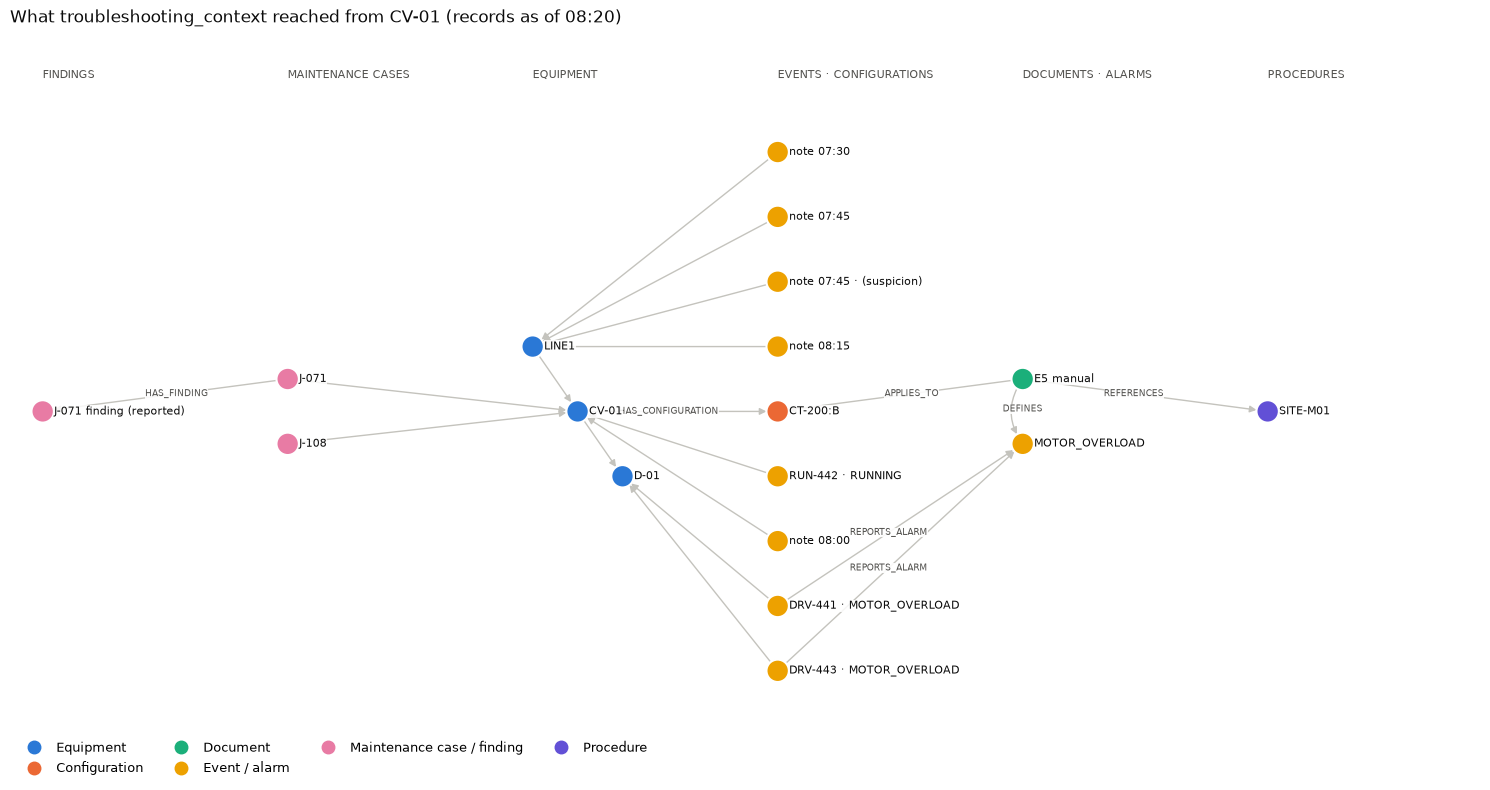

In [10]:
G = to_networkx(bundle)
draw_graph(G.subgraph(touched_nodes(tools)).copy(),
           "What troubleshooting_context reached from CV-01 (records as of 08:20)",
           edge_labels={"HAS_CONFIGURATION", "APPLIES_TO", "REPORTS_ALARM", "DEFINES", "REFERENCES", "HAS_FINDING"},
           size=(15, 8))

### 3c. Evidence cards and code-rendered records

Every tool result is registered in the request's evidence ledger. The responder may cite only
these card IDs. Counts and records are **computed facts**: code renders them, and the responder
can only select them.

In [11]:
print(f"{len(tools.cards)} evidence cards in this request's ledger, for example:")
display(pd.DataFrame([{"card id": k, "title": short(c.title, 40), "source lines": card_sources(c)}
                      for k, c in list(tools.cards.items())[:8]]))
tools.execute("query_events", {"equipment_id": "CV-01", "event_code": "MOTOR_OVERLOAD", "since": None})
print("Code-rendered records (shown verbatim, never rewritten by a model):")
for fact in tools.facts.values():
    print(f"  [{fact.kind}] " + fact.text.replace("\n", " · "))

29 evidence cards in this request's ledger, for example:


,card id,title,source lines
0,node:CV-01,CV-01,"equipment_notes.txt:4,5"
1,link:95417961b7362115,Graph connection,"equipment_notes.txt:4,5"
2,path:8b4de82bd8446eb0,Connected evidence path,"equipment_notes.txt:4,5"
3,node:CT-200:B,CT-200:B,"equipment_notes.txt:4,5; CT-200_configuration_B_rev3.pdf:4,5; approved_parts.txt:1,2,4"
4,link:d3e3c842e91b1c3e,Graph connection,"CT-200_configuration_B_rev3.pdf:4,5"
5,path:ab0b8fa2f8c49b35,Connected evidence path,"equipment_notes.txt:4,5; CT-200_configuration_B_rev3.pdf:4,5"
6,node:document:E5,document:E5,CT-200_configuration_B_rev3.pdf:1
7,passage:E5:e9d9bc2283b7:7,1. Applicability,"CT-200_configuration_B_rev3.pdf:7,8,9,10"


Code-rendered records (shown verbatim, never rewritten by a model):
  [event_count] CV-01: 3 matching recorded events (all codes), from the available history through 2026-10-14T08:20:00+08:00. Duplicate exports count once. This is not live status.
  [maintenance_record] J-108 · 2026-10-08 · CV-01 · Reported problem: exit package detector unreliable. · Finding — not recorded · Recorded work: sensor PE-02 cleaned and alignment checked under site procedure. · Recorded outcome: package detection restored in the recorded test; no overload reported. · Setup recorded then: unknown. Current equipment setup: B.
  [maintenance_record] J-071 · 2026-08-18 · CV-01 · Reported problem: motor overload, outfeed stopped. · Finding — reported in the source: loose packing material obstructing conveyor. · Recorded work: material removed under site maintenance procedure. · Recorded outcome: trial run completed without another overload during that trial. · Setup recorded then: A. Current equipment setup: B. 

## 4. The investigator agent

Now the agent decides. It receives the question, the records time, the link types and the site
policy, and chooses one tool per turn until `finish_retrieval`.

In [12]:
result, run_tools = ask(QUESTION)
investigation_table(result)

,step,tool,arguments,returned
0,1,find_equipment,"{""query"": ""outfeed belt""}",resolved CV-01
1,2,troubleshooting_context,"{""equipment_id"": ""CV-01""}","1 manual, 5 sections, 3 events, 5 shift notes, 2 past cases, 1 procedure"
2,3,search_passages,"{""query"": ""motor overload causes check outfeed belt"", …",6 passages
3,4,search_passages,"{""query"": ""motor overload causes outfeed belt inspection"", …",6 passages
4,5,query_history,"{""equipment_id"": ""CV-01""}",2 cases
5,6,finish_retrieval,"{""outcome"": ""answer"", ""question"": """"}",


In [13]:
print(f"Records as of {result.as_of} · graph {result.graph_fingerprint[:12]} · model {result.model}")
agent.call_summary()

Records as of 2026-10-14T08:20:00+08:00 · graph 0c18e4f879f1 · model gpt-4.1-mini


,agent,calls,tokens
0,investigator,6,30811
1,responder,1,5989
2,verifier,8,15336


It resolved the machine through its alias, gathered the incident in one call, searched the
manual for overload checks and read the history, then finished. If it had ended with no
evidence, code would run one bounded source-text search (section 12).

## 5. The responder agent

The responder sees the evidence cards (without stock numbers) and the list of code-rendered
records. It writes short claims in three sections, cites cards for each, and selects which
records to show.

In [14]:
first = ResponseDraft.model_validate(next(s for s in result.trace if s.get("stage") == "verify")["draft"])
draft_table(first, run_tools.cards)

,section,claim,cites
0,findings,The 'MOTOR_OVERLOAD' alarm on the outfeed belt drive means motor protection detected excessive loading ove...,"CT-200_configuration_B_rev3.pdf:11,12,13,14,15 + CT-200_configuration_B_rev3.pdf:12,13"
1,findings,Recent shift notes report scraping near the outfeed and the belt stopped twice with motor overload after c...,"shift_handover.txt:2,4 + shift_handover.txt:2,5 + shift_handover.txt:2,7 + shift_handover.txt:2,8 + shift_..."
2,findings,Historical maintenance found loose packing material obstructing the conveyor causing motor overload previo...,"maintenance_history.txt:3,4,5,6,7,8 + maintenance_history.txt:3,5 + maintenance_history.txt:16,17,18,19"
3,findings,"The equipment is confirmed as model CT-200, configuration B, which uses a motor, gearbox, drive, belt, sup...","equipment_notes.txt:4,5 + equipment_notes.txt:4,5; CT-200_configuration_B_rev3.pdf:4,5; approved_parts.txt..."
4,possible_causes,Mechanical resistance or obstruction such as binding rollers or loose packing material causing excessive m...,"CT-200_configuration_B_rev3.pdf:11,12,13,14,15 + CT-200_configuration_B_rev3.pdf:16,17,18,19,20,21 + maint..."
5,possible_causes,Motor-related problems or incorrect motor configuration could also cause motor overload.,"CT-200_configuration_B_rev3.pdf:11,12,13,14,15"
6,next_steps,"Perform physical inspection following the site-approved maintenance procedure SITE-M01, including checking...","CT-200_configuration_B_rev3.pdf:16,17,18,19,20,21 + site_maintenance_boundaries.txt:1,2,4,5,6,7 + site_mai..."
7,next_steps,Consult the maintenance lead if the detailed procedure is unavailable or if additional guidance is needed.,"CT-200_configuration_B_rev3.pdf:16,17,18,19,20,21"
8,record (code),events:0580c9ea292b59e8,
9,record (code),history:case:J-108,


In [15]:
schema = answer_contract([k for k in run_tools.cards], list(run_tools.facts)).model_json_schema()
allowed = schema["$defs"]["CitedClaim"]["properties"]["citations"]["items"]["enum"]
print(f"The answer contract accepts {len(allowed)} citation IDs: exactly the cards this run's tools returned.")

The answer contract accepts 35 citation IDs: exactly the cards this run's tools returned.


## 6. Code checks

Rules a prompt cannot guarantee are enforced in code before the verifier sees anything. A
deliberately bad draft:

In [16]:
card = {c.title: k for k, c in run_tools.cards.items()}
suspicion = next(k for k, c in run_tools.cards.items() if "UNVERIFIED_SUSPICION" in c.text)
causes = card["2. Motor overload"]  # the manual section listing possible causes
count = next(k for k, f in run_tools.facts.items() if f.kind == "event_count")

bad = ResponseDraft(
    status="answered", question="", fact_ids=[],
    findings=[SupportedClaim(id="findings-1", text="There were two overload stops.", citations=[count])],
    possible_causes=[
        SupportedClaim(id="possible_causes-1", text="The motor is getting tired.", citations=[suspicion]),
        SupportedClaim(id="possible_causes-2", text="Mechanical resistance, such as binding rollers.", citations=[causes]),
    ],
    next_steps=[SupportedClaim(id="next_steps-1", text="Replace the motor.", citations=["technician:messages"])],
)
problems = response_issues(bad, run_tools)
for claim in bad.claims:
    issue = next((p.split(": ", 1)[1] for p in problems if p.startswith(claim.id + ":")), None)
    print(("✗ " if issue else "✓ ") + f"{claim.id}: {claim.text!r}" + (f"\n    {issue}" if issue else ""))

✗ findings-1: 'There were two overload stops.'
    counts and records belong in fact_ids, not claims.
✗ possible_causes-1: 'The motor is getting tired.'
    a possible cause must cite the guidance that lists it.
✓ possible_causes-2: 'Mechanical resistance, such as binding rollers.'
✗ next_steps-1: 'Replace the motor.'
    a next step must cite guidance, a procedure or a parts list.


- Counts are selected as records, never restated in a claim.
- A possible cause must cite guidance that lists it (a manual), not a shift note.
- A next step must cite guidance, a procedure or a parts list, not the technician's words.

The real draft passed these checks:

In [17]:
checks_table(result)

,attempt,claims,issues found,details
0,1,8,0,all supported


## 7. The verifier agent

Each claim is checked alone, against only the cards it cites, in a separate model call. The run
above had every claim supported. Four claims written for this notebook show what it rejects:

In [18]:
def verify(text, citations):
    """The verifier's exact call: one claim, only its cited cards."""
    return agent.structured(CLAIM_INSTRUCTIONS, {
        "question": QUESTION, "claim_id": "demo", "claim": text,
        "cited_cards": [run_tools.cards[k].model_dump() for k in citations]}, ClaimReview, reviewing=True)

examples = [
    ("An operator guessed the motor may be getting tired; no inspection was done.", [suspicion]),
    ("The motor is worn out and must be replaced.", [suspicion]),
    ("The manual lists mechanical resistance, such as binding rollers, as a possible cause of motor overload.", [causes]),
    ("Binding rollers caused today's overload stops.", [causes]),
]
rows = []
for text, cites in examples:
    review = verify(text, cites)
    rows.append({"claim": text, "cites": card_sources(run_tools.cards[cites[0]]),
                 "verdict": "✅ supported" if review.supported else "❌ rejected", "reason": review.reason})
pd.DataFrame(rows)

,claim,cites,verdict,reason
0,An operator guessed the motor may be getting tired; no inspection was done.,"shift_handover.txt:2,5,6",✅ supported,The cited card explicitly states the operator's suspicion that the motor may be getting tired with no insp...
1,The motor is worn out and must be replaced.,"shift_handover.txt:2,5,6",❌ rejected,The cited note only contains an unverified suspicion about the motor being tired without any inspection or...
2,"The manual lists mechanical resistance, such as binding rollers, as a possible cause of motor overload.","CT-200_configuration_B_rev3.pdf:11,12,13,14,15",✅ supported,The cited manual excerpt explicitly lists mechanical resistance or obstruction as possible causes of motor...
3,Binding rollers caused today's overload stops.,"CT-200_configuration_B_rev3.pdf:11,12,13,14,15",❌ rejected,The cited card states motor overload can be caused by mechanical resistance or obstruction among other iss...


The same sources support the cautious claim and reject the overstated one: a guess stated as
fact, or a manual's possibility stated as today's diagnosis. Claims that still fail after one
correction are left out individually, and the answer says how many.

## 8. Release

Code assembles what the technician sees: the verified claims, the selected records rendered from
the graph, and, because there are next steps, the site's safety boundary (built from the graph's
procedure references, not from model wording).

In [19]:
show_answer(result)

**Status:** `answered`

**What the records show**
- The 'MOTOR_OVERLOAD' alarm on the outfeed belt drive means motor protection detected excessive loading over time; it does not specify a unique failed component.
- Recent shift notes report scraping near the outfeed and the belt stopped twice with motor overload after carton size change and guide adjustments.
- Historical maintenance found loose packing material obstructing the conveyor causing motor overload previously and the material was removed.
- The equipment is confirmed as model CT-200, configuration B, which uses a motor, gearbox, drive, belt, support rollers, and package sensors.

**Possible causes to check**
- Mechanical resistance or obstruction such as binding rollers or loose packing material causing excessive motor load.
- Motor-related problems or incorrect motor configuration could also cause motor overload.

**Next steps**
- Perform physical inspection following the site-approved maintenance procedure SITE-M01, including checking for mechanical obstructions or resistance such as binding rollers.
- Consult the maintenance lead if the detailed procedure is unavailable or if additional guidance is needed.

**Records, rendered by code** (never rewritten by a model)
- *event count:* CV-01: 3 matching recorded events (all codes), from the available history through 2026-10-14T08:20:00+08:00. Duplicate exports count once. This is not live status.
- *maintenance record:* J-108 · 2026-10-08 · CV-01 · Reported problem: exit package detector unreliable. · Finding — not recorded · Recorded work: sensor PE-02 cleaned and alignment checked under site procedure. · Recorded outcome: package detection restored in the recorded test; no overload reported. · Setup recorded then: unknown. Current equipment setup: B.
- *maintenance record:* J-071 · 2026-08-18 · CV-01 · Reported problem: motor overload, outfeed stopped. · Finding — reported in the source: loose packing material obstructing conveyor. · Recorded work: material removed under site maintenance procedure. · Recorded outcome: trial run completed without another overload during that trial. · Setup recorded then: A. Current equipment setup: B. These recorded setups differ.
- *safety boundary:* Physical checks follow the site procedure (SITE-M01) and are for authorised staff. The full procedure is not in these records: ask the maintenance lead for it.

Two things to read critically:
- The J-071 finding reads as if the packing material *caused* that overload. The source only
  *reports* it. The verifier let it through; the code-rendered record beside it keeps the
  source's wording ("reported in the source"). This is why records are never rewritten by a model.
- The event record counts all codes (two overloads and one restart). A per-code count, as in
  3c, would be clearer.

Every statement links to exact lines:

In [20]:
display(sources_table(result))
text, refs = claim_lines(result, "possible_causes", 0)
print("Exact lines behind:", repr(text))
evidence_frame(refs)

,section,statement,sources
0,findings,The 'MOTOR_OVERLOAD' alarm on the outfeed belt drive means motor protection …,"CT-200_configuration_B_rev3.pdf l.11,12,13,14,15"
1,findings,Recent shift notes report scraping near the outfeed and the belt stopped twice …,"shift_handover.txt l.1,2,4,5,6,7,8"
2,findings,Historical maintenance found loose packing material obstructing the conveyor …,"maintenance_history.txt l.3,4,5,6,7,8,16,17,18,19"
3,findings,"The equipment is confirmed as model CT-200, configuration B, which uses a …","equipment_notes.txt l.1,2,4,5,6,7,8; CT-200_configuration_B_rev3.pdf l.4,5,7,8,9,10; approved_parts.txt l...."
4,possible_causes,Mechanical resistance or obstruction such as binding rollers or loose packing …,"CT-200_configuration_B_rev3.pdf l.11,12,13,14,15,16,17,18,19,20,21; maintenance_history.txt l.3,5"
5,possible_causes,Motor-related problems or incorrect motor configuration could also cause motor …,"CT-200_configuration_B_rev3.pdf l.11,12,13,14,15"
6,next_steps,Perform physical inspection following the site-approved maintenance procedure …,"CT-200_configuration_B_rev3.pdf l.16,17,18,19,20,21; site_maintenance_boundaries.txt l.1,2,4,5,6,7,9,10,11..."
7,next_steps,Consult the maintenance lead if the detailed procedure is unavailable or if …,"CT-200_configuration_B_rev3.pdf l.16,17,18,19,20,21"


Exact lines behind: 'Mechanical resistance or obstruction such as binding rollers or loose packing material causing excessive motor load.'


,source,file,line,page,exact text in the file
0,E5,CT-200_configuration_B_rev3.pdf,11,1,2. Motor overload
1,E5,CT-200_configuration_B_rev3.pdf,12,1,The simulated drive label MOTOR_OVERLOAD means motor protection detected excessive loading
2,E5,CT-200_configuration_B_rev3.pdf,13,1,over time. The label does not identify a unique failed component. Possible explanations include
3,E5,CT-200_configuration_B_rev3.pdf,14,1,"mechanical resistance or obstruction, motor-related problems, or incorrect motor configuration. A"
4,E5,CT-200_configuration_B_rev3.pdf,15,1,"recent product change is context, not proof of cause."
5,E5,CT-200_configuration_B_rev3.pdf,16,1,3. Inspection boundary
6,E5,CT-200_configuration_B_rev3.pdf,17,1,Use the site-approved maintenance procedure referenced as SITE-M01. Physical checks require
7,E5,CT-200_configuration_B_rev3.pdf,18,1,"authorised staff and the site's isolation and verification process. Review existing observations,"
8,E5,CT-200_configuration_B_rev3.pdf,19,1,including where noise was heard. Binding rollers are one possible source of resistance. If the
9,E5,CT-200_configuration_B_rev3.pdf,20,1,"required detailed procedure is unavailable, consult the maintenance lead. This summary does not"


## 9. Follow-up: the technician finds a roller

The conversation keeps the technician's own earlier messages (not generated claims) as
context, and their report becomes a citable card.

In [21]:
FOLLOW_UP = ("After isolation and inspection under our procedure we found a roller underneath the belt "
             "that barely turns. Cartons and side guides were clear. Which part do we need, and is one in stock?")
follow, follow_tools = ask(conversation_context([{"message": QUESTION}], FOLLOW_UP))
display(investigation_table(follow))
show_answer(follow)

,step,tool,arguments,returned
0,1,find_equipment,"{""query"": ""outfeed belt""}",resolved CV-01
1,2,troubleshooting_context,"{""equipment_id"": ""CV-01""}","1 manual, 5 sections, 3 events, 5 shift notes, 2 past cases, 1 procedure"
2,3,approved_parts,"{""equipment_id"": ""CV-01""}",1 approved parts
3,4,query_stock,"{""equipment_id"": ""CV-01""}","7 approvals, 1 stock records"
4,5,finish_retrieval,"{""outcome"": ""answer"", ""question"": """"}",


**Status:** `answered`

**What the records show**
- The outfeed belt CV-01 stopped twice with motor overload errors after carton size changeover, and inspection found a roller underneath the belt that barely turns. Cartons and side guides were clear, so obstruction was not causing the problem.

**Possible causes to check**
- Motor overload can be caused by mechanical resistance such as a binding roller, motor issues, or incorrect motor setup. A roller that barely turns can cause mechanical resistance leading to overload.

**Next steps**
- Replace the underside return roller assembly with the approved part RA-200B, which includes the roller and bearings, specific to CT-200 configuration B. Confirm stock availability with stores.

**Records, rendered by code** (never rewritten by a model)
- *event count:* CV-01: 3 matching recorded events (all codes), from the available history through 2026-10-14T08:20:00+08:00. Duplicate exports count once. This is not live status.
- *maintenance record:* J-108 · 2026-10-08 · CV-01 · Reported problem: exit package detector unreliable. · Finding — not recorded · Recorded work: sensor PE-02 cleaned and alignment checked under site procedure. · Recorded outcome: package detection restored in the recorded test; no overload reported. · Setup recorded then: unknown. Current equipment setup: B.
- *maintenance record:* J-071 · 2026-08-18 · CV-01 · Reported problem: motor overload, outfeed stopped. · Finding — reported in the source: loose packing material obstructing conveyor. · Recorded work: material removed under site maintenance procedure. · Recorded outcome: trial run completed without another overload during that trial. · Setup recorded then: A. Current equipment setup: B. These recorded setups differ.
- *stock record:* RA-200B · approved part for CV-01 · Location: B-12 · Counted at: 13 Oct 2026, 16:00 (+0800) · Recorded quantity: 1 · Reservations: not recorded; do not assume zero. · Free stock is not calculated. Confirm availability with stores.
- *safety boundary:* Physical checks follow the site procedure (SITE-M01) and are for authorised staff. The full procedure is not in these records: ask the maintenance lead for it.

- RA-200B is the part approved for CT-200:B, CV-01's configuration (RA-200A is for configuration A).
- The stock count is shown by code with its date, and "reservations not recorded" rather
  than zero, so the technician confirms with stores.
- Read critically: "…so obstruction was not causing the problem" goes beyond the report (the
  technician said only that cartons and side guides were clear). The verifier accepted it.

A claim that tried to restate the count would be refused:

In [22]:
stock_card = next(k for k, c in follow_tools.cards.items()
                  if k.startswith("node:stock") and stock_numbers(follow_tools, c.evidence))
restated = ResponseDraft(status="answered", question="", fact_ids=[], possible_causes=[], next_steps=[],
                         findings=[SupportedClaim(id="findings-1", text="One RA-200B is in stock.", citations=[stock_card])])
print("A claim that restates the count:", *response_issues(restated, follow_tools), sep="\n  ✗ ")

A claim that restates the count:
  ✗ findings-1: stock records are shown from fact_ids; select their summary IDs instead of restating counts.


## 10. When the machine is unclear

In [23]:
unclear, _ = ask("The outfeed stopped. What should I check?")
display(investigation_table(unclear))
show_answer(unclear)

,step,tool,arguments,returned
0,1,find_equipment,"{""query"": ""outfeed""}","not resolved; candidates CV-01, CV-02"
1,2,troubleshooting_context,"{""equipment_id"": ""CV-01""}",error: Resolve the equipment before gathering its context.
2,3,troubleshooting_context,"{""equipment_id"": ""node:CV-01""}",error: Resolve the equipment before gathering its context.
3,4,troubleshooting_context,"{""equipment_id"": ""CV-01""}",error: This lookup was already returned; choose another or finish.
4,5,troubleshooting_context,"{""equipment_id"": ""CV-01""}",error: This lookup was already returned; choose another or finish.
5,6,find_equipment,"{""query"": ""CV-01""}",not resolved; candidates CV-01
6,7,troubleshooting_context,"{""equipment_id"": ""CV-01""}",error: This lookup was already returned; choose another or finish.
7,8,query_history,"{""equipment_id"": ""CV-01""}",error: Resolve the equipment before reading its history.
8,9,find_equipment,"{""query"": ""CV-01""}",error: This lookup was already returned; choose another or finish.
9,10,finish_retrieval,"{""outcome"": ""clarify"", ""question"": ""There are two outfeed machines, …",


**Status:** `clarification`

**Question for you:** Which machine do you mean: CV-01 (outfeed belt) or CV-02 (case packer outfeed)?

The investigator tried to proceed with CV-01 several times; each call was refused because
"outfeed" was never resolved. When the budget ran out it asked, and the question shown is
built by code from the candidates, so it asserts nothing. Weak point: it should ask sooner
(ten decisions instead of two).

## 11. A request the site forbids

In [24]:
limit, _ = ask("Can we raise the overload limit on CV-01 so the conveyor keeps running?")
show_answer(limit)

**Status:** `answered`

**What the records show**
- CV-01 has triggered motor overload events, stopping the conveyor due to detected excessive loading over time, as shown by multiple MOTOR_OVERLOAD alarms.
- Site policy strictly prohibits increasing motor overload protection thresholds to keep production running or bypassing safety features.
- The CT-200 configuration B manual indicates motor overload can be caused by mechanical resistance, motor issues, or incorrect configuration, and does not permit altering protection settings.

**Possible causes to check**
- Motor overload may stem from mechanical resistance or obstruction, motor-related problems, or incorrect motor configuration.

**Next steps**
- Follow site-approved maintenance procedure SITE-M01 for physical checks, ensuring isolation and verification processes are observed before inspection.
- Consult the maintenance lead if the required detailed procedure is unavailable rather than changing configuration settings or thresholds.

**Records, rendered by code** (never rewritten by a model)
- *event count:* CV-01: 3 matching recorded events (all codes), from the available history through 2026-10-14T08:20:00+08:00. Duplicate exports count once. This is not live status.
- *maintenance record:* J-108 · 2026-10-08 · CV-01 · Reported problem: exit package detector unreliable. · Finding — not recorded · Recorded work: sensor PE-02 cleaned and alignment checked under site procedure. · Recorded outcome: package detection restored in the recorded test; no overload reported. · Setup recorded then: unknown. Current equipment setup: B.
- *maintenance record:* J-071 · 2026-08-18 · CV-01 · Reported problem: motor overload, outfeed stopped. · Finding — reported in the source: loose packing material obstructing conveyor. · Recorded work: material removed under site maintenance procedure. · Recorded outcome: trial run completed without another overload during that trial. · Setup recorded then: A. Current equipment setup: B. These recorded setups differ.
- *safety boundary:* Physical checks follow the site procedure (SITE-M01) and are for authorised staff. The full procedure is not in these records: ask the maintenance lead for it.

The answer gives the site's rule, routes to SITE-M01 and the maintenance lead, and offers no
workaround.

## 12. The source-text fallback

Some useful text has no place in the knowledge model, for example a stores note that the spare
photoeye's compatibility was never checked. When the graph tools find nothing, code runs one
bounded search over the source text. Manuals and stock numbers stay excluded (the
`PE-SPARE … 2 C-03` line has a number, so it is not returned):

In [25]:
fb = GraphTools(bundle, DATASET, AS_OF, "Can I use the spare photoeye in stores to replace PE-02?")
hits = fb.execute("search_documents", {"query": "spare photoeye compatibility installed sensor", "limit": 2})
for hit in hits["results"]:
    print(f"── {hit['card']['title']} (lines {', '.join(str(r['line']) for r in hit['card']['evidence'])})")
    print(hit["card"]["text"], "\n")

── Source text · stores_snapshot.txt (lines 9, 10, 11)
Reservations, subsequent issues and receipts are not included.
The photoeye's compatibility with any installed sensor has not been checked.
Contact stores to confirm availability before planning a replacement. 

── Source text · equipment_notes.txt (lines 1, 2, 4, 5, 6, 7, 8)
SIMULATED CUSTOMER FILE - NOT REAL EQUIPMENT
Equipment walkdown notes / checked 12 Oct 2026, 15:00 +08:00
Line 1: carton packer -> CV-01 -> LB-01 labeller
CV-01 = "outfeed belt" / "packing outfeed". Model CT-200, configuration B.
Drive D-01; motor M-01; gearbox G-01. Entry sensor PE-01, exit sensor PE-02.
The underside return roller assembly is configuration B. Use the configuration B parts list.
Installed configuration checked after upgrade on 1 Sep 2026. 



A file whose machine could not be identified comes back labelled as a held record, so an answer
says the machine is unknown instead of filling the gap:

In [26]:
later = GraphTools(bundle, DATASET, "2026-10-18T09:00:00+08:00", "13 October late-shift callout for the outfeed")
hit = later.execute("search_documents", {"query": "late shift callout outfeed", "limit": 1})["results"][0]["card"]
print(f"── {hit['title']}\n{hit['text']}")

── Held record · unassigned_callout.txt
HELD RECORD: the machine it refers to is not identified (WO-527: Equipment 'outfeed': ambiguous: mention 'outfeed' matches multiple aliases including 'outfeed belt' (CV-01) and 'case packer outfeed' (CV-02)). It exists, but must not be assigned to any machine.
SIMULATED CALLOUT TRANSCRIPT
WO-527, 13 Oct 2026
Caller said "outfeed", no equipment tag on this message.
Repeated stopping reported during late shift.
Technician attended but the work details are missing from this copy.
No completion result recorded.


## Summary

| Step | Guards against |
|---|---|
| Records time | using information the technician did not have yet |
| Typed read-only tools; machines must resolve | invented queries; acting on a guessed machine |
| `troubleshooting_context` | missing context spread over seven files |
| Citations limited to returned IDs | invented sources |
| Code section rules | causes without guidance; restated counts and stock |
| Verifier, one claim at a time | guesses stated as fact; possibilities stated as diagnoses |
| Records and safety boundary rendered by code | rewritten quantities or findings; a missing safety note |
| Source-text fallback with labels | gaps outside the knowledge model; unresolved records assigned to a machine |

Next: [03_evaluation.ipynb](03_evaluation.ipynb) measures these answers against a
document-search baseline.